# Practice #1. "Trend analysis"

Smooth a series, then pull its trend out.

Fill in the cells tagged `graded`. They are marked and graded automatically, so
keep every function name and signature exactly as given. Untagged cells are
yours to change.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose

# DATA_DIR is injected when the grader imports this notebook; when you run the
# notebook yourself it falls back to ../data relative to this file.
def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())

## 0. Data reading and visualization

`opsd_germany_daily.csv` has four columns. `Wind` and `Solar` are empty
before 2012, so a bare `df.dropna()` also drops six years of good `Consumption`.
Select your two columns first, then drop.

In [2]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    # сначала выбираю только нужные колонки, чтобы dropna не выбросил строки из-за пустых Wind/Solar
    df = pd.read_csv(path)[[time_col, value_col]].copy()
    df = df.rename(columns={time_col: "ds", value_col: "y"})
    df["ds"] = pd.to_datetime(df["ds"])
    # удаляю пропуски уже после выбора колонок и ставлю дату в индекс
    df = df.dropna().set_index("ds")
    return df["y"].astype(float)

In [3]:
series = load_series(DATA_DIR / "opsd_germany_daily.csv", "Date", "Consumption")
print(f"{len(series)} points from {series.index.min():%Y-%m-%d} "
      f"to {series.index.max():%Y-%m-%d}")
series.head()

4383 points from 2006-01-01 to 2017-12-31


ds
2006-01-01    1069.184
2006-01-02    1380.521
2006-01-03    1442.533
2006-01-04    1457.217
2006-01-05    1477.131
Name: y, dtype: float64

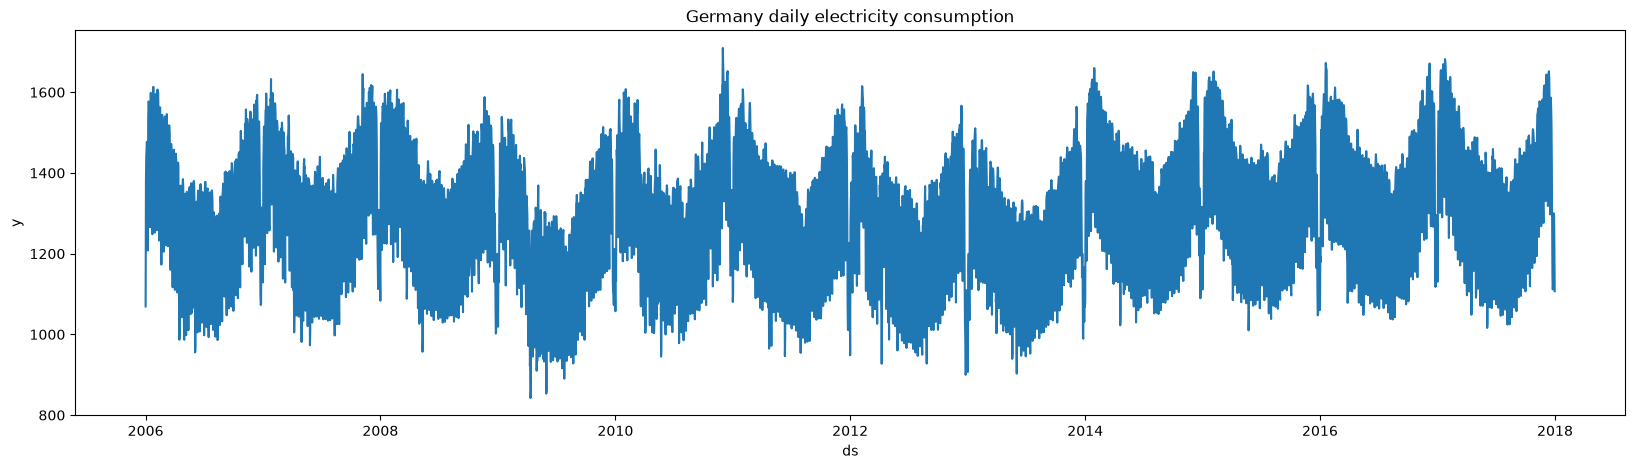

In [4]:
plt.figure(figsize=(20, 5))
plt.plot(series)
plt.ylabel("y")
plt.xlabel("ds")
plt.title("Germany daily electricity consumption");

## 1. Timeseries smoothing

### 1.1 Moving average

#### Centered moving average
$$x[t] = \frac{x[t - \lfloor n/2 \rfloor] + \ldots + x[t] + \ldots + x[t + \lfloor n/2 \rfloor]}{n}$$

#### Trailing moving average
$$x[t] = \frac{x[t - n + 1] + \ldots + x[t - 1] + x[t]}{n}$$

where $n$ is the window size. Only the trailing average is usable for
forecasting: the centred one reads values from the future.

In [5]:
def centered_moving_average(series, window):
    """Window centred on each point."""
    # беру окно симметрично вокруг текущей точки (center=True)
    return series.rolling(window=window, center=True).mean()


def trailing_moving_average(series, window):
    """Window ending at each point."""
    # обычное скользящее среднее по прошлым значениям вплоть до текущего
    return series.rolling(window=window, center=False).mean()

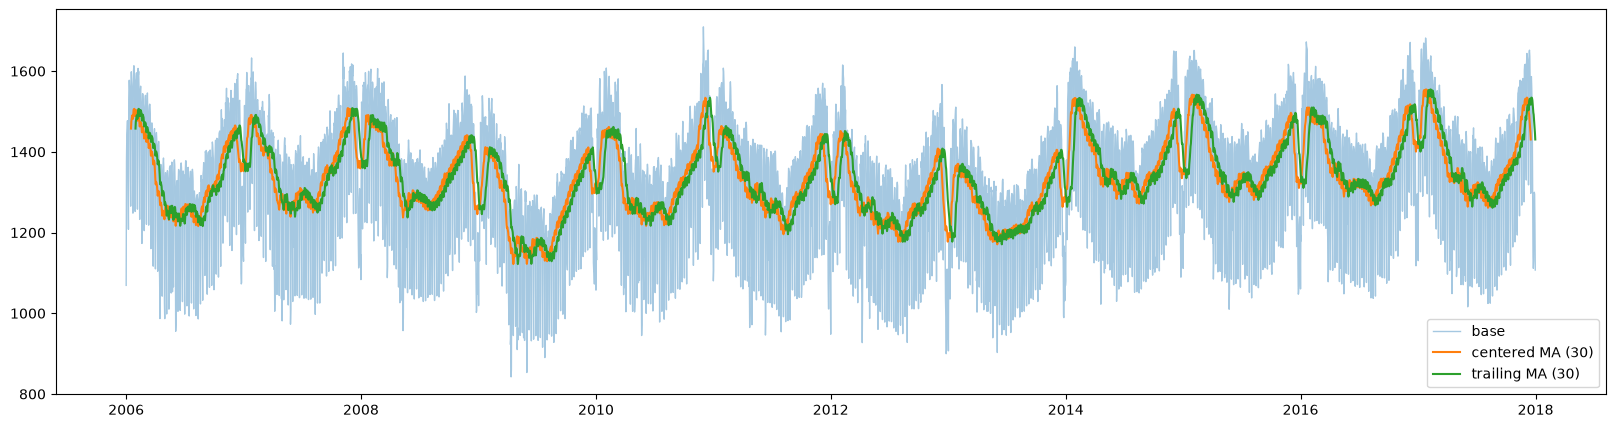

In [6]:
plt.figure(figsize=(20, 5))
plt.plot(series, linewidth=1, alpha=0.4, label="base")
plt.plot(centered_moving_average(series, 30), label="centered MA (30)")
plt.plot(trailing_moving_average(series, 30), label="trailing MA (30)")
plt.legend();

Smooth the data with several window sizes and compare.

**Question.** How does the window size change the smoothed series, and why is
the trailing average shifted to the right relative to the centred one?

**Ответ.** Чем больше окно, тем сильнее подавляются короткие колебания (недельные и месячные) и тем плавнее кривая: стандартное отклонение падает с 100.42 при `window=7` до 88.65 (`window=30`), 75.09 (`window=90`) и 41.24 (`window=365`, где остаётся фактически только межгодовая динамика), при этом по краям теряется `window - 1` точек в виде `NaN`. Trailing MA сдвинут вправо примерно на пол-окна ($\approx n/2$, около 15 дней для `window=30`), потому что в момент $t$ он усредняет только прошлые значения $[t-n+1, t]$ (центр тяжести окна находится в $t - (n-1)/2$), тогда как центрированное среднее берёт окно $[t-\lfloor n/2\rfloor, t+\lfloor n/2\rfloor]$ с центром ровно в $t$.

window=  7: std(cma)=100.42, NaN=6
window= 30: std(cma)=88.65, NaN=29
window= 90: std(cma)=75.09, NaN=89
window=365: std(cma)=41.24, NaN=364


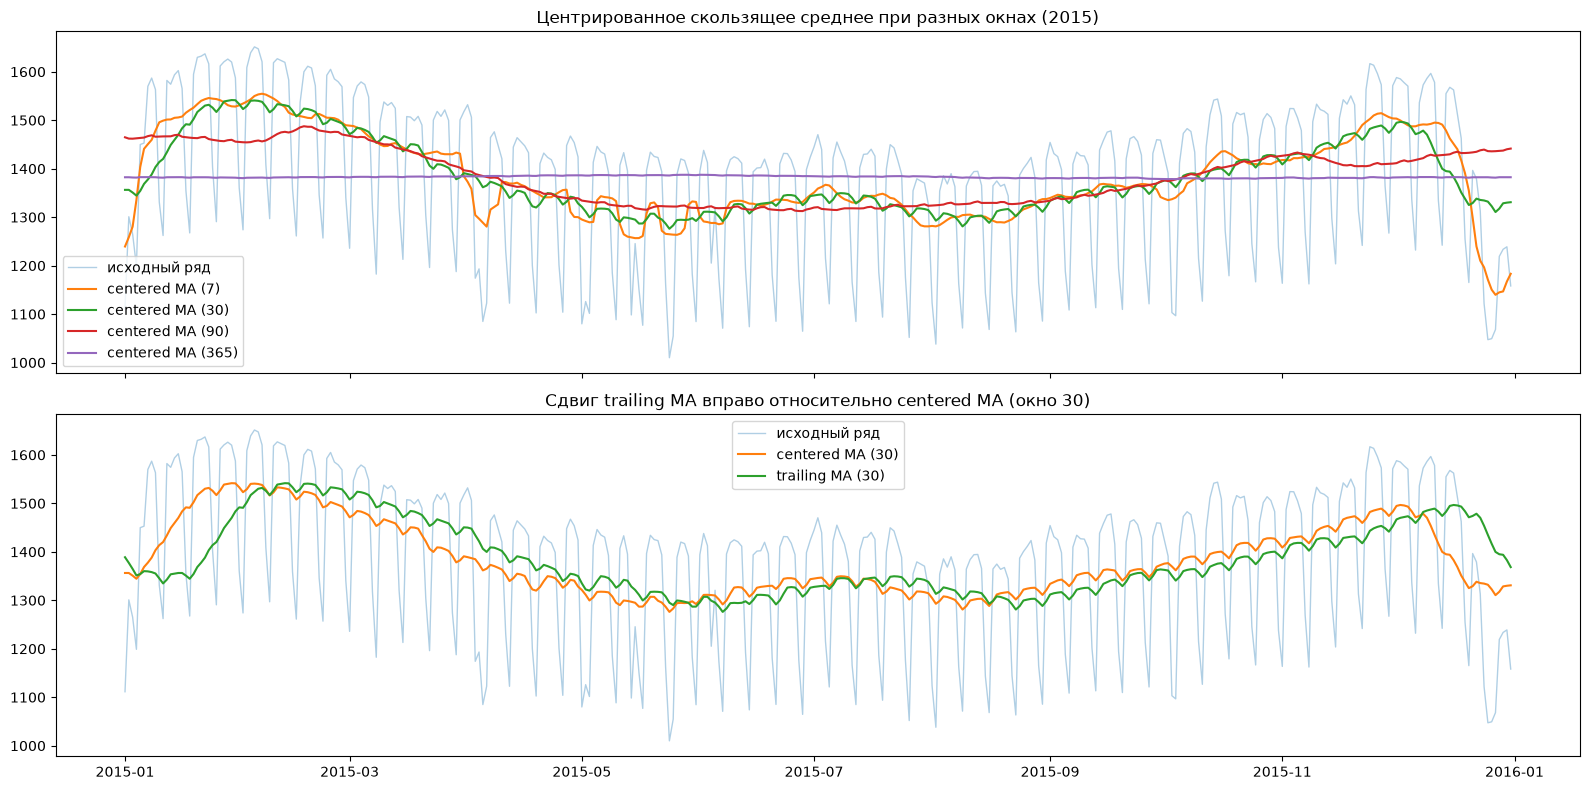

In [7]:
# сравниваю разные размеры окна на одном 2015 году, чтобы лучше видеть сдвиг и сглаживание
sub = series.loc["2015"]
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

axes[0].plot(sub, linewidth=1, alpha=0.35, label="исходный ряд")
for w in (7, 30, 90, 365):
    cma = centered_moving_average(series, w).loc["2015"]
    axes[0].plot(cma, label=f"centered MA ({w})")
    print(f"window={w:3d}: std(cma)={centered_moving_average(series, w).std():.2f}, "
          f"NaN={centered_moving_average(series, w).isna().sum()}")
axes[0].set_title("Центрированное скользящее среднее при разных окнах (2015)")
axes[0].legend()

axes[1].plot(sub, linewidth=1, alpha=0.35, label="исходный ряд")
axes[1].plot(centered_moving_average(series, 30).loc["2015"], label="centered MA (30)")
axes[1].plot(trailing_moving_average(series, 30).loc["2015"], label="trailing MA (30)")
axes[1].set_title("Сдвиг trailing MA вправо относительно centered MA (окно 30)")
axes[1].legend()
plt.tight_layout();

### 1.2 Exponential smoothing

The two libraries agree to floating-point precision — but only with the
right arguments.

- `ewm(alpha=a)` defaults to `adjust=True`: a renormalised weighted average, not
  the textbook recursion. It does **not** match statsmodels.
- `adjust=False` gives exactly `s[0] = x[0]`, `s[t] = a·x[t] + (1-a)·s[t-1]`.

Implement both. The assertion below must pass.

In [8]:
def exponential_smoothing(series, alpha):
    """SES via pandas: s[0] = x[0], s[t] = a*x[t] + (1-a)*s[t-1]."""
    # ставлю adjust=False, чтобы получилась точная рекуррентная формула без перенормировки весов
    return series.ewm(alpha=alpha, adjust=False).mean()


def exponential_smoothing_statsmodels(series, alpha):
    """Same recursion via statsmodels; return the level as a Series."""
    # задаю начальный уровень как первое значение ряда и фиксирую alpha через optimized=False
    model = SimpleExpSmoothing(
        series,
        initialization_method="known",
        initial_level=series.iloc[0],
    )
    fit = model.fit(smoothing_level=alpha, optimized=False)
    return fit.level

In [9]:
pandas_smoothed = exponential_smoothing(series, 0.3)
statsm_smoothed = exponential_smoothing_statsmodels(series, 0.3)
largest_gap = (pandas_smoothed - statsm_smoothed).abs().max()
print(f"max |pandas - statsmodels| = {largest_gap:.3e}")
assert largest_gap < 1e-8, "the two implementations must agree"

max |pandas - statsmodels| = 0.000e+00


C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


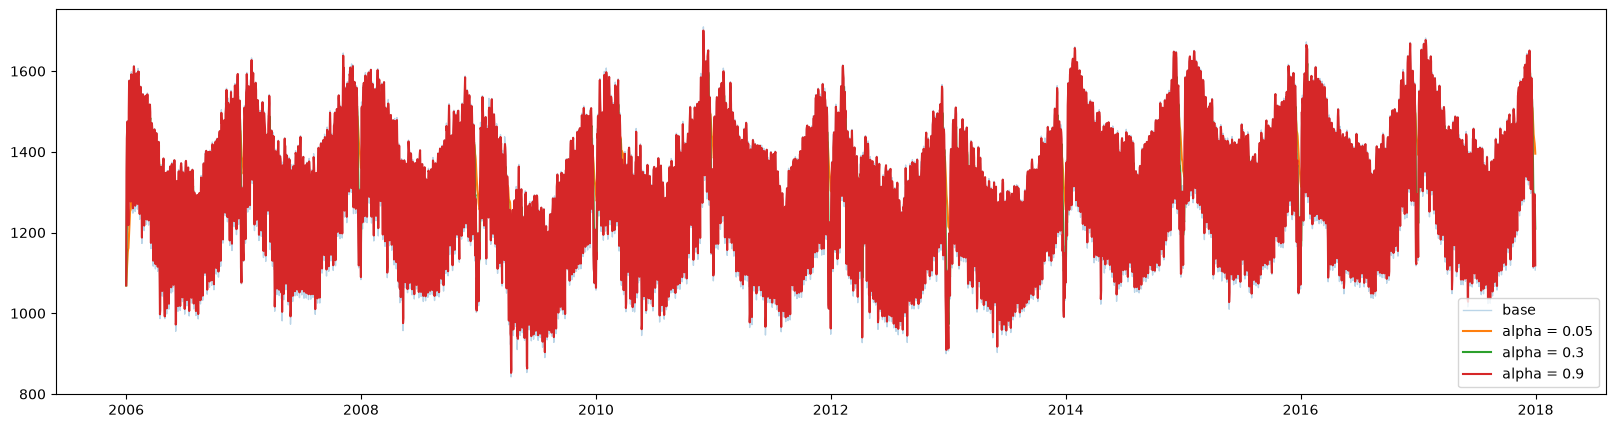

In [10]:
plt.figure(figsize=(20, 5))
plt.plot(series, linewidth=1, alpha=0.3, label="base")
for a in (0.05, 0.3, 0.9):
    plt.plot(exponential_smoothing(series, a), label=f"alpha = {a}")
plt.legend();

**Question.** What does alpha do to the smoothed series, and what
happens in the limits alpha -> 0 and alpha -> 1?

**Ответ.** Параметр $\alpha \in (0, 1]$ задаёт вес текущего наблюдения $x[t]$ относительно накопленного уровня $s[t-1]$ и управляет «памятью» сглаживания (на графике это хорошо видно для $\alpha = 0.05, 0.3, 0.9$). При $\alpha \to 0$ вес новых наблюдений стремится к нулю, ряд почти не реагирует на колебания и вырождается в константу на уровне начального значения $s[0] = x[0]$. При $\alpha \to 1$ прошлый уровень перестаёт учитываться, и сглаженный ряд $s[t]$ полностью совпадает с исходным $x[t]$ без какого-либо сглаживания.

### 1.3 Double exponential smoothing

Holt's method adds a trend component: a level `l[t]` smoothed by alpha
and a slope `b[t]` smoothed by beta.

In [11]:
def double_exponential_smoothing(series, alpha, beta, trend="add"):
    """Holt's linear trend smoothing; return the fitted level as a Series."""
    # модель Хольта с оценкой начальных уровня и наклона и фиксированными alpha, beta
    model = ExponentialSmoothing(
        series,
        trend=trend,
        initialization_method="estimated",
    )
    fit = model.fit(smoothing_level=alpha, smoothing_trend=beta, optimized=False)
    return fit.level

C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


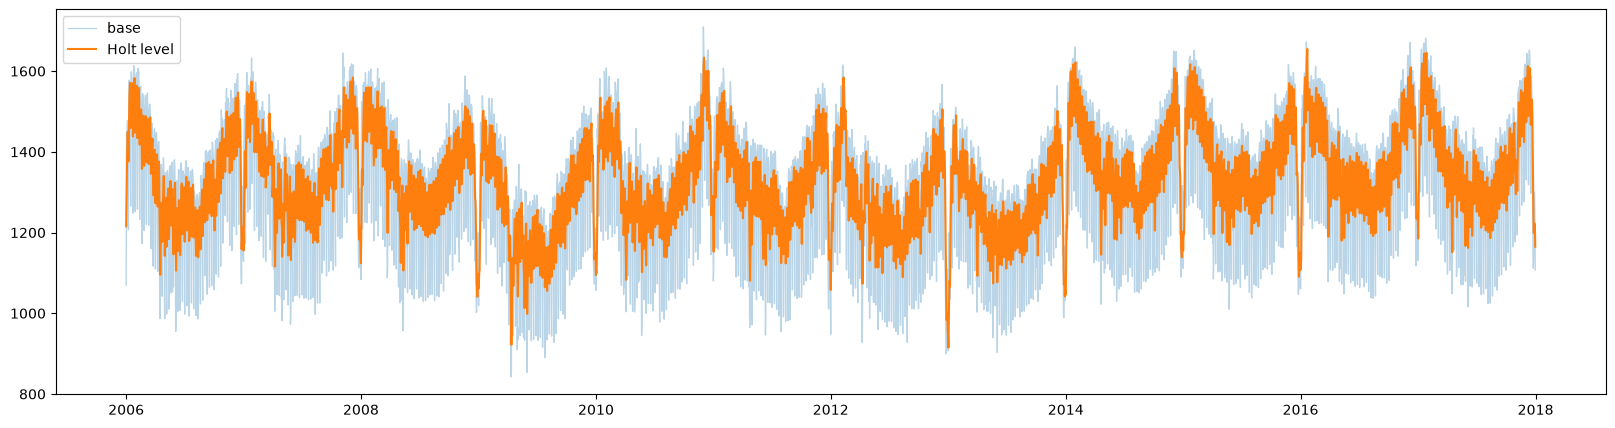

In [12]:
plt.figure(figsize=(20, 5))
plt.plot(series, linewidth=1, alpha=0.3, label="base")
plt.plot(double_exponential_smoothing(series, 0.3, 0.1), label="Holt level")
plt.legend();

Try several alpha/beta pairs and both trend types (`"add"`, `"mul"`).

**Questions.** What does beta control? Are alpha and beta related?

statsmodels may raise `ConvergenceWarning` here. Don't silence it — it means the
fit never settled, and the numbers below it are not trustworthy.

**Ответ.** Параметр $\beta$ управляет скоростью обновления оценки наклона (тренда) $b[t]$: чем больше $\beta$, тем быстрее модель подстраивается под изменение направления ряда, но при слишком больших значениях наклон начинает реагировать на сезонный шум. На практике $\alpha$ и $\beta$ связаны общим балансом между гладкостью и скоростью реакции (обычно берут $\beta \le \alpha$, например в наших прогонах `(0.1, 0.02)`, `(0.3, 0.1)`, `(0.6, 0.3)`, где с ростом пары RMSE к исходному ряду падает со 133.23 до 70.65, а `std(level)` растёт со 102.61 до 141.15; аддитивный и мультипликативный тренды дают здесь очень близкие результаты).

C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\fedor\AppData\Roaming\Python\Python314\site-packages\statsmodels\tsa\base\tsa_model.py:480: Val

trend=add, alpha=0.1, beta=0.02: std(level)=102.61, RMSE(vs base)=133.23
trend=add, alpha=0.3, beta=0.1: std(level)=114.02, RMSE(vs base)=108.42
trend=add, alpha=0.6, beta=0.3: std(level)=141.15, RMSE(vs base)=70.65
trend=mul, alpha=0.1, beta=0.02: std(level)=104.40, RMSE(vs base)=133.99
trend=mul, alpha=0.3, beta=0.1: std(level)=113.90, RMSE(vs base)=108.35
trend=mul, alpha=0.6, beta=0.3: std(level)=141.23, RMSE(vs base)=70.14


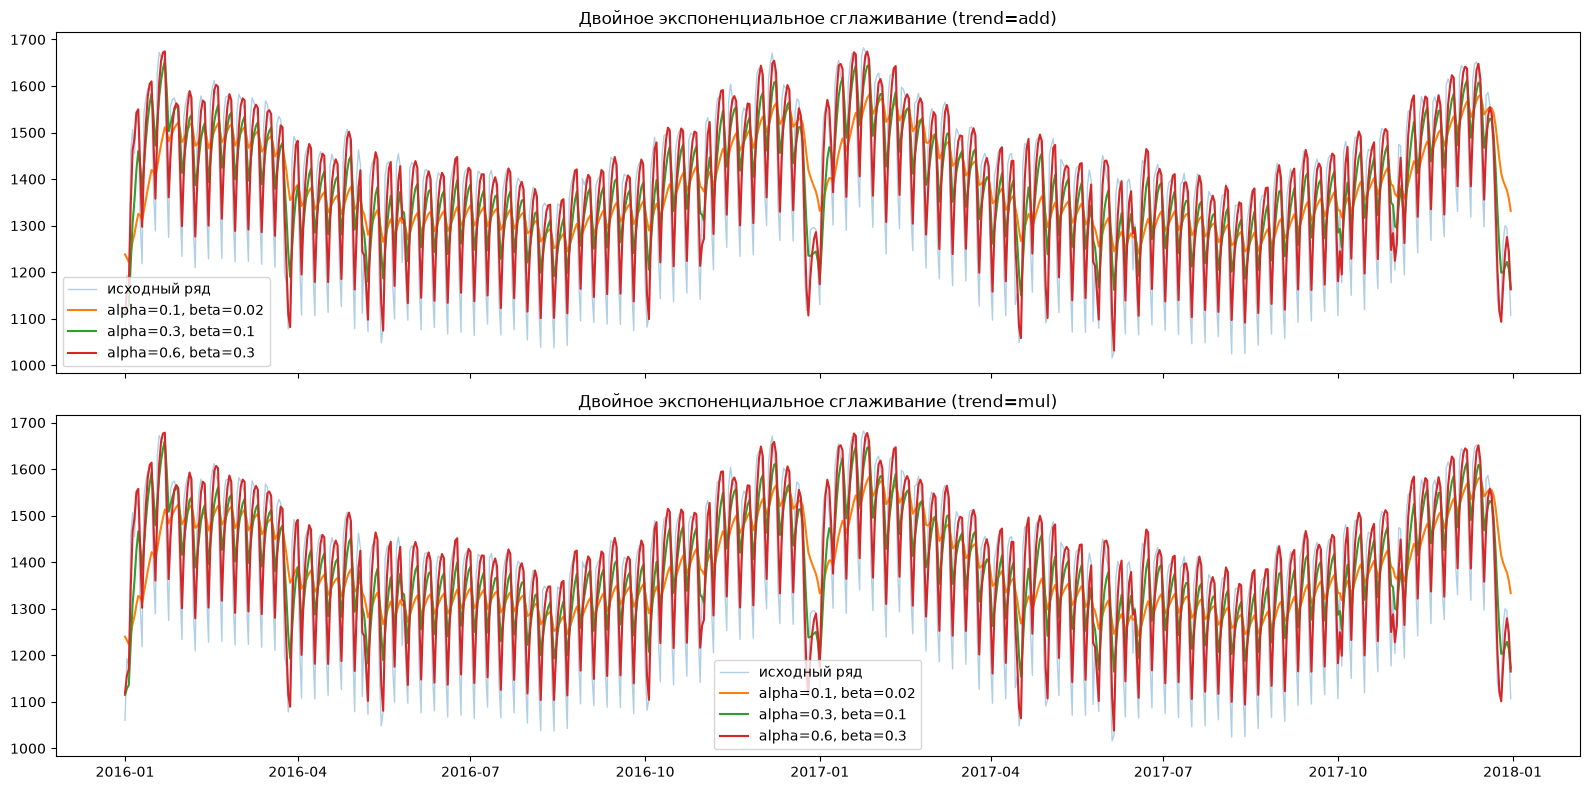

In [13]:
# проверяю несколько пар (alpha, beta) и оба типа тренда на 2016-2017 годах
pairs = [(0.1, 0.02), (0.3, 0.1), (0.6, 0.3)]
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

for idx, trend_type in enumerate(["add", "mul"]):
    axes[idx].plot(series.loc["2016":], linewidth=1, alpha=0.35, label="исходный ряд")
    for a, b in pairs:
        lvl = double_exponential_smoothing(series, a, b, trend=trend_type)
        axes[idx].plot(lvl.loc["2016":], label=f"alpha={a}, beta={b}")
        rmse = np.sqrt(mean_squared_error(series, lvl))
        print(f"trend={trend_type}, alpha={a}, beta={b}: std(level)={lvl.std():.2f}, RMSE(vs base)={rmse:.2f}")
    axes[idx].set_title(f"Двойное экспоненциальное сглаживание (trend={trend_type})")
    axes[idx].legend()
plt.tight_layout();

## 2. Trend extraction

### 2.1 Linear regression

In [14]:
def linear_trend(series):
    """Least-squares straight line through the series, as a Series."""
    # кодирую время индексами 0, 1, ..., n-1 и привожу к столбцу для sklearn
    X = np.arange(len(series)).reshape(-1, 1)
    reg = LinearRegression().fit(X, series.to_numpy())
    # возвращаю значения прямой на том же индексе
    return pd.Series(reg.predict(X), index=series.index, name=series.name)


def decomposition_trend(series, period, model="additive"):
    """Trend component from seasonal_decompose.

    Keep the NaNs at both ends: that is where a centred window does not fit.
    """
    # извлекаю компоненту тренда из классической декомпозиции, NaN на концах не трогаю
    res = seasonal_decompose(series, model=model, period=period)
    return res.trend

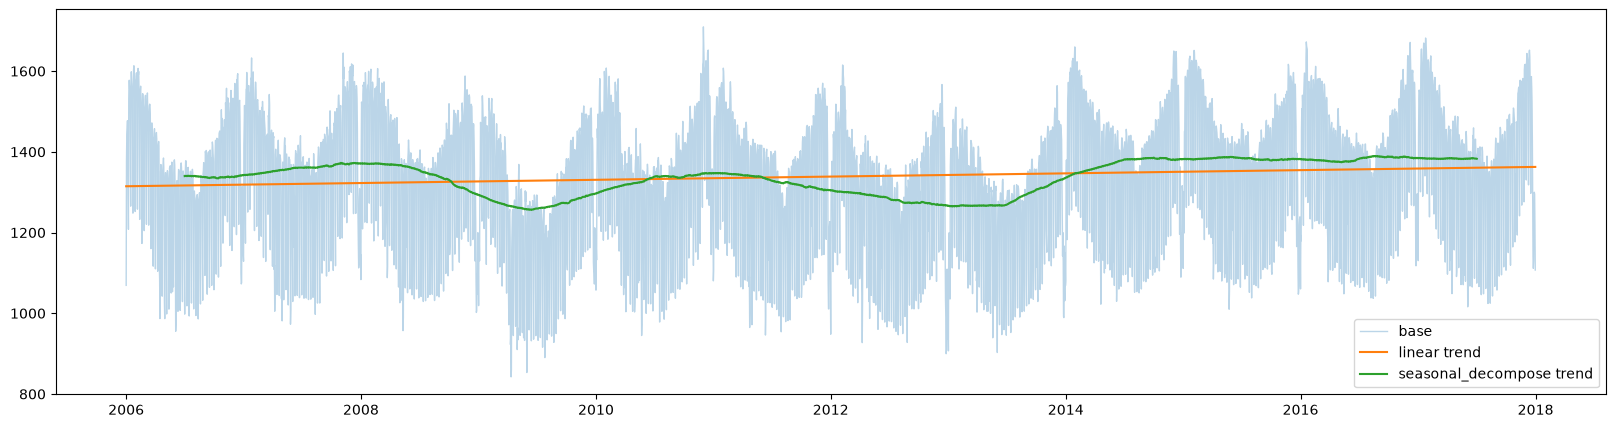

In [15]:
trend_line = linear_trend(series)
trend_decomposed = decomposition_trend(series, period=365)

plt.figure(figsize=(20, 5))
plt.plot(series, linewidth=1, alpha=0.3, label="base")
plt.plot(trend_line, label="linear trend")
plt.plot(trend_decomposed, label="seasonal_decompose trend")
plt.legend();

### 2.2 Comparing the two trends

`seasonal_decompose(period=365)` uses a centred moving average, so the first and
last ~182 days have no value. Compare only where both trends are defined.

In [16]:
both_defined = trend_decomposed.notna()
error = mean_squared_error(trend_decomposed[both_defined], trend_line[both_defined])
print(f"points compared: {int(both_defined.sum())} of {len(series)}")
print(f"MSE between the two trend estimates: {error:.2f}")

points compared: 4019 of 4383
MSE between the two trend estimates: 1491.74


**Question.** Repeat the comparison on a series you smoothed first. Does
smoothing change the linear trend? Why, or why not?

**Ответ.** На исходном ряде линейный тренд проходит от 1314.73 до 1362.63 (рост +47.90), а MSE между ним и трендом из `seasonal_decompose` по 4019 точкам составляет 1491.74. После предварительного сглаживания (SES с $\alpha=0.1$) линейный тренд меняется незначительно: старт 1312.47, конец 1363.83 (рост +51.36), максимальное отклонение от исходной прямой равно 2.26, а MSE к `seasonal_decompose` остаётся почти прежним — 1484.27 (и 1492.48 после MA(30)). Так происходит потому, что сглаживание подавляет высокочастотный шум и колебания, но не меняет долгосрочный наклон ряда: симметричные колебания вокруг прямой почти не влияют на МНК-оценку (небольшой сдвиг связан только с краевым эффектом или отбрасыванием `NaN` на концах).

Линейный тренд (исходный): старт=1314.73, конец=1362.63, изменение=47.90
Линейный тренд (SES 0.1):  старт=1312.47, конец=1363.83, изменение=51.36
Max |linear(SES) - linear(raw)| = 2.26
MSE(seasonal_decompose vs linear) на SES(0.1): 1484.27
MSE(seasonal_decompose vs linear) на MA(30):   1492.48


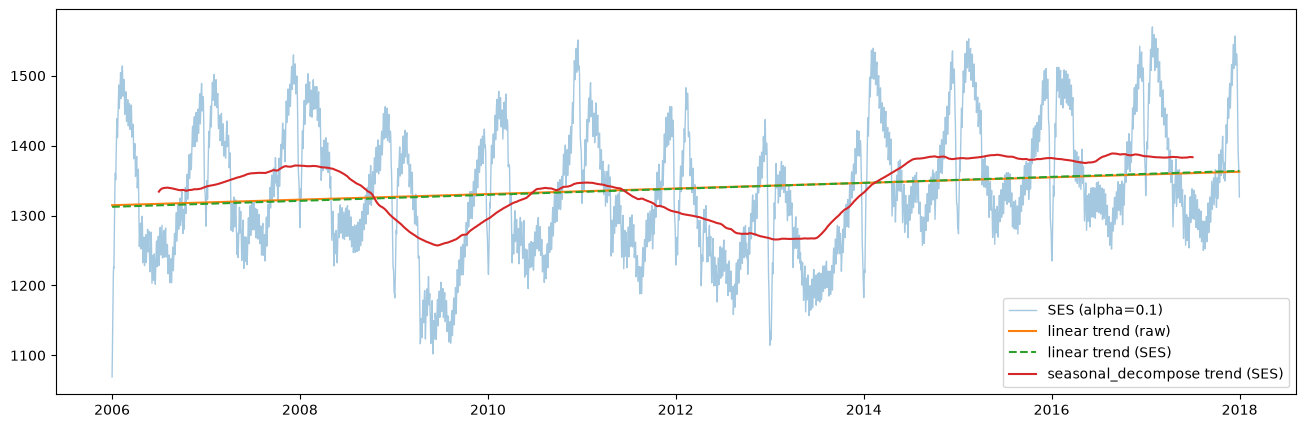

In [17]:
# сначала сглаживаю ряд (SES с alpha=0.1 и центрированным окном 30), затем сравниваю тренды
smoothed_ses = exponential_smoothing(series, 0.1)
trend_lin_raw = linear_trend(series)
trend_lin_ses = linear_trend(smoothed_ses)
trend_dec_ses = decomposition_trend(smoothed_ses, period=365)

mask_ses = trend_dec_ses.notna()
mse_ses = mean_squared_error(trend_dec_ses[mask_ses], trend_lin_ses[mask_ses])
max_lin_diff = (trend_lin_ses - trend_lin_raw).abs().max()

# также проверяю сглаживание центрированным окном 30 (без NaN по краям)
smoothed_ma = centered_moving_average(series, 30).dropna()
trend_lin_ma = linear_trend(smoothed_ma)
trend_dec_ma = decomposition_trend(smoothed_ma, period=365)
mask_ma = trend_dec_ma.notna()
mse_ma = mean_squared_error(trend_dec_ma[mask_ma], trend_lin_ma[mask_ma])

# сравниваю наклоны прямых (разница за 1 шаг и за весь период)
slope_raw = trend_lin_raw.iloc[-1] - trend_lin_raw.iloc[0]
slope_ses = trend_lin_ses.iloc[-1] - trend_lin_ses.iloc[0]
print(f"Линейный тренд (исходный): старт={trend_lin_raw.iloc[0]:.2f}, конец={trend_lin_raw.iloc[-1]:.2f}, изменение={slope_raw:.2f}")
print(f"Линейный тренд (SES 0.1):  старт={trend_lin_ses.iloc[0]:.2f}, конец={trend_lin_ses.iloc[-1]:.2f}, изменение={slope_ses:.2f}")
print(f"Max |linear(SES) - linear(raw)| = {max_lin_diff:.2f}")
print(f"MSE(seasonal_decompose vs linear) на SES(0.1): {mse_ses:.2f}")
print(f"MSE(seasonal_decompose vs linear) на MA(30):   {mse_ma:.2f}")

plt.figure(figsize=(16, 5))
plt.plot(smoothed_ses, linewidth=1, alpha=0.4, label="SES (alpha=0.1)")
plt.plot(trend_lin_raw, label="linear trend (raw)")
plt.plot(trend_lin_ses, "--", label="linear trend (SES)")
plt.plot(trend_dec_ses, label="seasonal_decompose trend (SES)")
plt.legend();